# 01. Exploración del dataset cardiovascular

Caracterizar el conjunto original y explicar sus variables.

**Dataset principal:** `data/nuevo_dataset/cardio_train.csv`. Este cuaderno no ejecuta entrenamientos. Los resultados históricos se leen de archivos conservados; no se sustituyen por nuevas ejecuciones.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/nuevo_dataset/cardio_train.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.experimento import (
    ORIGINAL, RESULTADOS, VARIABLES, NOMBRES, cargar_datos, reglas_calidad,
    cargar_metricas, comparar_ejecuciones, tabla_configuracion, verificar_configuracion,
    construir_cnn, tabla_modelo, dibujar_arquitectura, guardar_figura_nueva,
    importancia_guardada, resumen_dataset, verificar_predicciones, tensorflow_disponible,
)

In [2]:
df = cargar_datos(ORIGINAL)
print("Dimensiones:", df.shape)
display(df.head())
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum()}))
print("Columnas:", df.columns.tolist())
print("Nulos:", int(df.isna().sum().sum()))
print("Duplicados exactos (incluye id):", int(df.duplicated().sum()))
print("Repeticiones sin id:", int(df.drop(columns="id").duplicated().sum()))

Dimensiones: (70000, 13)
Columnas: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
Nulos: 0
Duplicados exactos (incluye id): 0
Repeticiones sin id: 24


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


,tipo,nulos
id,int64,0
age,int64,0
gender,int64,0
height,int64,0
weight,float64,0
ap_hi,int64,0
ap_lo,int64,0
cholesterol,int64,0
gluc,int64,0
smoke,int64,0


## Diccionario de variables
Los códigos categóricos son categorías, no magnitudes continuas. La edad original está en días. `id` identifica registros y `cardio` es el objetivo; quedan 11 predictoras. Coincidencias sin identificador no demuestran por sí solas que sean el mismo paciente.

In [3]:
descripciones = {"id": "Identificador; excluido del modelo", "age": "Edad en días; se convierte a años dividiendo entre 365.25", "gender": "Sexo codificado (1/2)", "height": "Altura en centímetros", "weight": "Peso en kilogramos", "ap_hi": "Presión arterial sistólica", "ap_lo": "Presión arterial diastólica", "cholesterol": "Colesterol: categorías 1 normal, 2 superior, 3 muy superior", "gluc": "Glucosa: categorías 1 normal, 2 superior, 3 muy superior", "smoke": "Tabaquismo: 0/1", "alco": "Consumo de alcohol: 0/1", "active": "Actividad física: 0/1", "cardio": "Objetivo: 0 ausencia, 1 presencia de enfermedad cardiovascular"}
display(pd.DataFrame({"variable": list(descripciones), "descripcion": list(descripciones.values())}))
display(df.describe().T)
display(df["cardio"].value_counts().sort_index().to_frame("registros"))
display(df["cardio"].value_counts(normalize=True).sort_index().mul(100).to_frame("porcentaje"))

,variable,descripcion
0,id,Identificador; excluido del modelo
1,age,Edad en días; se convierte a años dividiendo e...
2,gender,Sexo codificado (1/2)
3,height,Altura en centímetros
4,weight,Peso en kilogramos
5,ap_hi,Presión arterial sistólica
6,ap_lo,Presión arterial diastólica
7,cholesterol,"Colesterol: categorías 1 normal, 2 superior, 3..."
8,gluc,"Glucosa: categorías 1 normal, 2 superior, 3 mu..."
9,smoke,Tabaquismo: 0/1


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


,registros
cardio,
0,35021
1,34979


,porcentaje
cardio,
0,50.03
1,49.97


01_exploracion_dataset:celda-4:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


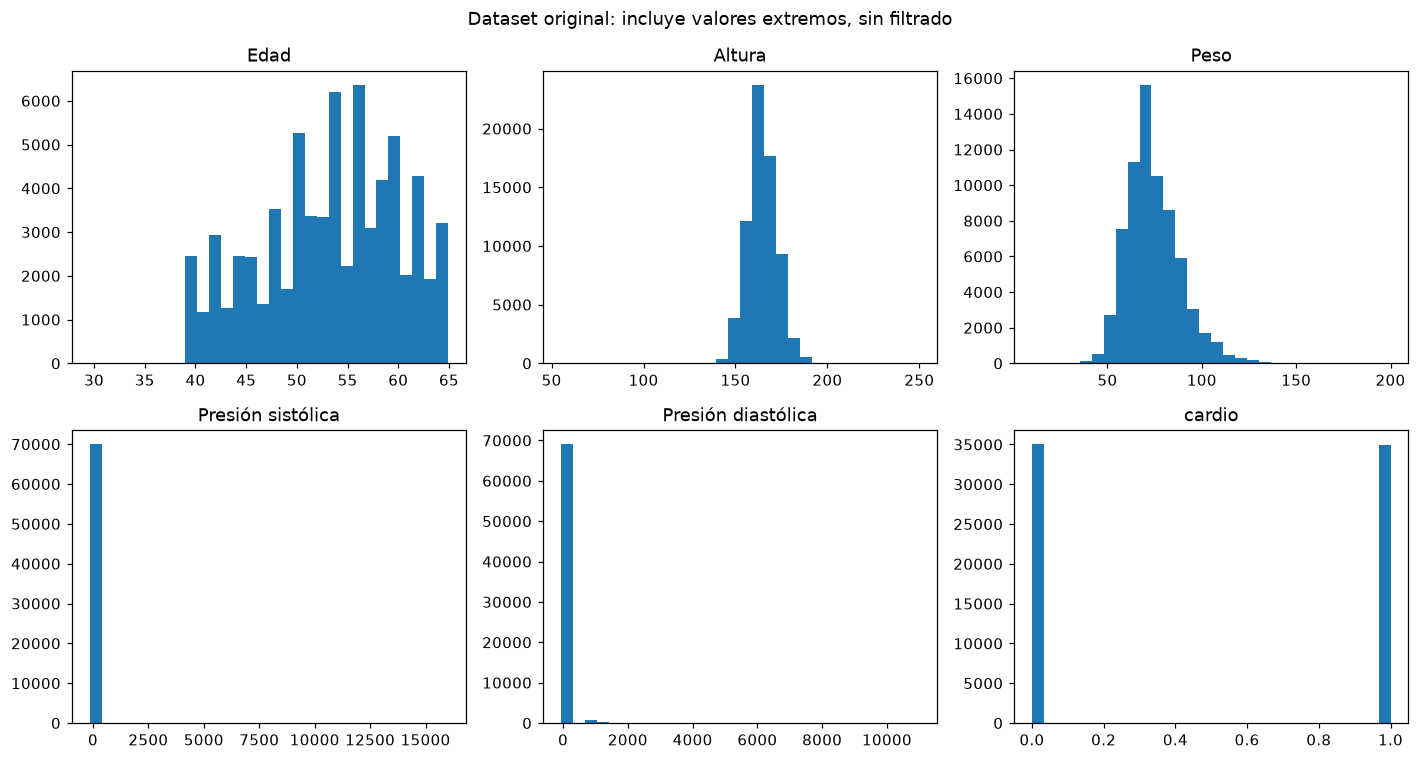

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
explorar = df.assign(age=df.age / 365.25)
for ax, col in zip(axes.flat, ["age", "height", "weight", "ap_hi", "ap_lo", "cardio"]):
    ax.hist(explorar[col], bins=30)
    ax.set_title(NOMBRES.get(col, col))
fig.suptitle("Dataset original: incluye valores extremos, sin filtrado")
fig.tight_layout()
plt.show()

Los valores extremos se mantienen visibles en esta exploración. Su identificación y tratamiento se documentan en 02 y 03; el original permanece intacto.